# Milestone 1: BM3D baseline on SIDD

Project 17, self-supervised real-world image denoising without paired data.

In M2 we want to train a denoiser that never sees clean images. Before that we need to
know how good a classical denoiser already is on this data, otherwise we have nothing to
compare against. That is what this notebook does: it measures BM3D on real smartphone
noise from SIDD.

Nothing is trained here. No model, no DND. That is M2 and M3 work.

Run `store_sidd.ipynb` first to download the dataset (about 6.2 GB).

## 1. Imports

In [16]:
%pip install -q -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\CE977RH\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [17]:
import json
import platform
import random
import time
from pathlib import Path

import bm3d
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity

project_root = Path.cwd().parent
results_dir = project_root / "results"
figures_dir = results_dir / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("project:", project_root)
print("python :", platform.python_version())

project: c:\Users\CE977RH\Downloads\Computer_Vision\self-supervised-image-denoising
python : 3.14.6


## 2. Find the data

We ask `kagglehub` for the path instead of writing the cache folder by hand, so this cell
keeps working if the cache ever moves. It returns straight away once the data is already
downloaded.

`truststore` has to come first on our network, otherwise the Kaggle request fails with a
certificate error.

In [18]:
import truststore

truststore.inject_into_ssl()

import kagglehub

sidd_root = Path(kagglehub.dataset_download("rajat95gupta/smartphone-image-denoising-dataset"))
sidd_root = sidd_root / "SIDD_Small_sRGB_Only"
data_dir = sidd_root / "Data"

print(sidd_root)
print("found:", data_dir.is_dir())

C:\Users\CE977RH\.cache\kagglehub\datasets\rajat95gupta\smartphone-image-denoising-dataset\versions\1\SIDD_Small_sRGB_Only
found: True


## 3. What is inside

In [19]:
folders = sorted(p.name for p in data_dir.iterdir() if p.is_dir())

print("folders:", len(folders))
for name in folders[:5]:
    print(" ", name)

folders: 160
  0001_001_S6_00100_00060_3200_L
  0002_001_S6_00100_00020_3200_N
  0003_001_S6_00100_00060_3200_H
  0004_001_S6_00100_00060_4400_L
  0005_001_S6_00100_00060_4400_N


Each folder is one capture and the name encodes the settings:

`<instance>_<scene>_<phone>_<ISO>_<shutter>_<temperature>_<brightness>`

So `0001_001_S6_00100_00060_3200_L` is capture 1, of scene 1, on a Galaxy S6, ISO 100,
low light. The second field is the one we care about: it says which physical scene was
photographed. There are 160 captures but only 10 scenes, because each scene was shot
many times with different phones and settings.

## 4. Look at one pair

Quick eda

0001_001_S6_00100_00060_3200_L
size: (3000, 5328, 3)


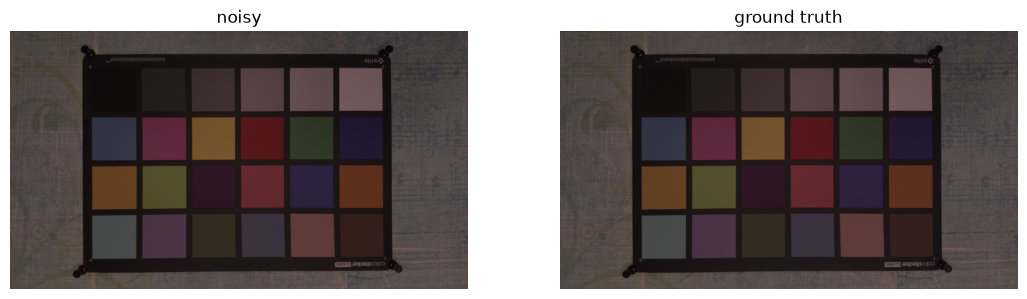

In [20]:
def load_image(path):
    return np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0


sample_dir = data_dir / folders[0]
sample_noisy = load_image(next(sample_dir.glob("NOISY_SRGB_*.PNG")))
sample_gt = load_image(next(sample_dir.glob("GT_SRGB_*.PNG")))

print(folders[0])
print("size:", sample_noisy.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(sample_noisy)
axes[0].set_title("noisy")
axes[1].imshow(sample_gt)
axes[1].set_title("ground truth")
for ax in axes:
    ax.axis("off")
plt.show()

## 5. Zoom in on the noise

At full size the two images look almost identical. The noise only shows up when we crop
in, which is also why we will work on crops instead of whole images.

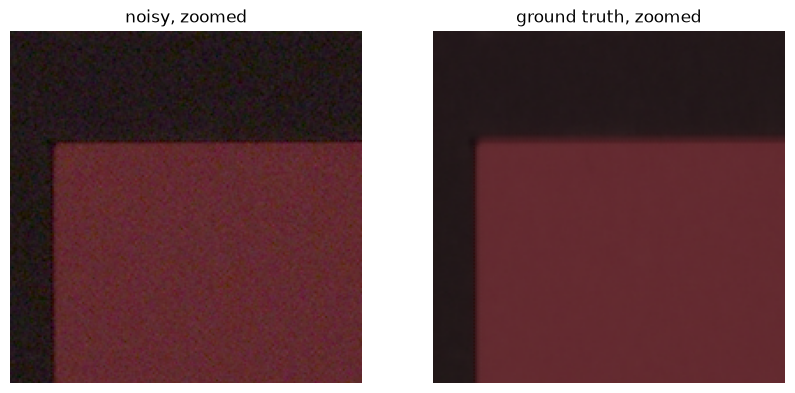

mean difference: 0.01763889


In [21]:
height, width = sample_noisy.shape[:2]
top, left = height // 2, width // 2

zoom_noisy = sample_noisy[top : top + 200, left : left + 200]
zoom_gt = sample_gt[top : top + 200, left : left + 200]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(zoom_noisy)
axes[0].set_title("noisy, zoomed")
axes[1].imshow(zoom_gt)
axes[1].set_title("ground truth, zoomed")
for ax in axes:
    ax.axis("off")
plt.show()

print("mean difference:", np.abs(zoom_noisy - zoom_gt).mean())

## 6. Settings

One seed controls everything random in this notebook, so the whole thing reruns the same
way.

The sigma grid goes up to 0.24 on purpose. Our first run only went to 0.16 and BM3D
picked that top value, which means the real best could have been higher and we would
never have seen it. Picking a value at the edge of the grid is not really a calibration,
so we widened it.

In [22]:
SEED = 681

SCENES_TRAIN, SCENES_VAL, SCENES_TEST = 6, 2, 2

CROP_SIZE = 256
CROPS_PER_CAPTURE = 4

BORDER = 4  # dropped on each side so filter edge artefacts are never scored
SSIM_WINDOW = 11
SSIM_SIGMA = 1.5

SIGMA_GRID = (0.02, 0.04, 0.08, 0.12, 0.16, 0.20, 0.24)

print("seed", SEED, "| crop", CROP_SIZE, "| border", BORDER)
print("sigma grid", SIGMA_GRID)

seed 681 | crop 256 | border 4
sigma grid (0.02, 0.04, 0.08, 0.12, 0.16, 0.2, 0.24)


## 7. Collect every capture

In [23]:
def list_captures(data_dir):
    captures = []
    for folder in sorted(p for p in data_dir.iterdir() if p.is_dir()):
        captures.append(
            {
                "name": folder.name,
                "scene": folder.name.split("_")[1],
                "noisy": next(folder.glob("NOISY_SRGB_*.PNG")),
                "gt": next(folder.glob("GT_SRGB_*.PNG")),
            }
        )
    return captures


captures = list_captures(data_dir)
scenes = sorted({c["scene"] for c in captures})

print("captures:", len(captures))
print("scenes  :", len(scenes))
print()
for scene in scenes:
    count = sum(1 for c in captures if c["scene"] == scene)
    print(f"scene {scene}: {count} captures")

captures: 160
scenes  : 10

scene 001: 28 captures
scene 002: 15 captures
scene 003: 15 captures
scene 004: 15 captures
scene 005: 19 captures
scene 006: 19 captures
scene 007: 20 captures
scene 008: 20 captures
scene 009: 6 captures
scene 010: 3 captures


## 8. Split by scene, not by capture

This is the part that is easy to get wrong. If we shuffled the 160 captures and split
them, the same room would end up in both the training and the test set, just shot at a
different ISO. The test score would then be far too optimistic.

So we shuffle the 10 scenes instead and give 6 to train, 2 to validation, 2 to test. The
splits end up slightly uneven in size because some scenes were photographed more often
than others, and that is fine.

In [25]:
shuffled = list(scenes)
random.Random(SEED).shuffle(shuffled)

scene_groups = {
    "train": shuffled[:SCENES_TRAIN],
    "val": shuffled[SCENES_TRAIN : SCENES_TRAIN + SCENES_VAL],
    "test": shuffled[SCENES_TRAIN + SCENES_VAL :],
}

splits = {
    name: [c for c in captures if c["scene"] in group]
    for name, group in scene_groups.items()
}

split_summary = {}
for name in ("train", "val", "test"):
    group = sorted(scene_groups[name])
    n_captures = len(splits[name])
    split_summary[name] = {
        "scenes": group,
        "captures": n_captures,
        "crops": n_captures * CROPS_PER_CAPTURE,
    }
    print(f"{name:5s} scenes {','.join(group):28s} {n_captures:3d} captures  {n_captures * CROPS_PER_CAPTURE:4d} crops")

(results_dir / "split.json").write_text(
    json.dumps({"seed": SEED, "splits": split_summary}, indent=2), encoding="utf-8"
)
print("\nsaved split.json")


train scenes 001,003,005,008,009,010       91 captures   364 crops
val   scenes 002,004                       30 captures   120 crops
test  scenes 006,007                       39 captures   156 crops

saved split.json


## 9. Cutting crops

BM3D on a full 3000 by 5000 image is far too slow, so we score fixed 256 by 256 crops
instead. Four per capture, placed at the quarter points of the image. Fixed positions
rather than random ones means a rerun gives exactly the same crops.

[(622, 1204), (622, 3868), (2122, 1204), (2122, 3868)]


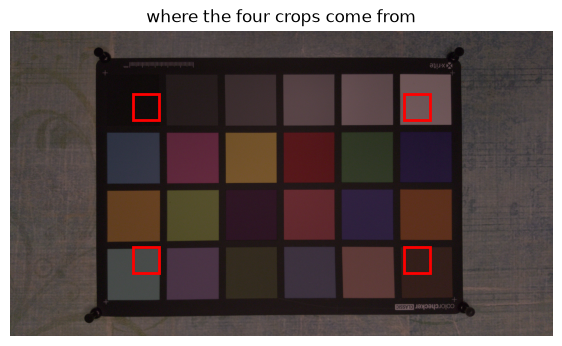

In [26]:
def crop_boxes(height, width):
    half = CROP_SIZE // 2
    rows = [height // 4 - half, 3 * height // 4 - half]
    cols = [width // 4 - half, 3 * width // 4 - half]
    return [(r, c) for r in rows for c in cols]


boxes = crop_boxes(height, width)
print(boxes)

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(sample_noisy)
for row, col in boxes:
    ax.add_patch(plt.Rectangle((col, row), CROP_SIZE, CROP_SIZE, fill=False, color="red", lw=2))
ax.set_title("where the four crops come from")
ax.axis("off")
plt.show()

In [27]:
def get_crops(split_name, limit=None):
    """All crops of a split, in a fixed order. limit takes a seeded subsample."""
    crops = []
    for capture in splits[split_name]:
        noisy = load_image(capture["noisy"])
        gt = load_image(capture["gt"])
        for index, (row, col) in enumerate(crop_boxes(*noisy.shape[:2])):
            crops.append(
                {
                    "name": capture["name"],
                    "index": index,
                    "noisy": noisy[row : row + CROP_SIZE, col : col + CROP_SIZE],
                    "gt": gt[row : row + CROP_SIZE, col : col + CROP_SIZE],
                }
            )
    if limit is not None and limit < len(crops):
        picked = sorted(random.Random(SEED).sample(range(len(crops)), limit))
        crops = [crops[i] for i in picked]
    return crops


val_crops = get_crops("val")
print("validation crops:", len(val_crops))
print("first one:", val_crops[0]["name"], val_crops[0]["noisy"].shape)

validation crops: 120
first one: 0034_002_GP_00100_00160_3200_N (256, 256, 3)


## 10. Metrics

PSNR and SSIM, both on clipped values in [0, 1] with 4 pixels cut off every side.

The SSIM settings are written out because SSIM is not one fixed number: different
libraries use different windows and you cannot compare results across them. We use the
Wang et al. setting, an 11 pixel Gaussian window with sigma 1.5.

In [28]:
def prepare(image):
    image = np.clip(image.astype(np.float64), 0.0, 1.0)
    return image[BORDER:-BORDER, BORDER:-BORDER]


def psnr(pred, target):
    pred, target = prepare(pred), prepare(target)
    mse = np.mean((pred - target) ** 2)
    if mse == 0:
        return float("inf")
    return float(10 * np.log10(1.0 / mse))


def ssim(pred, target):
    pred, target = prepare(pred), prepare(target)
    return float(
        structural_similarity(
            target,
            pred,
            data_range=1.0,
            channel_axis=2,
            gaussian_weights=True,
            win_size=SSIM_WINDOW,
            sigma=SSIM_SIGMA,
            use_sample_covariance=False,
        )
    )


check = val_crops[0]
print("image against itself:", psnr(check["gt"], check["gt"]), ssim(check["gt"], check["gt"]))
print(f"noisy against clean : {psnr(check['noisy'], check['gt']):.3f} dB, {ssim(check['noisy'], check['gt']):.5f}")

image against itself: inf 1.0
noisy against clean : 35.663 dB, 0.87057


Comparing an image with itself gives infinite PSNR and SSIM of exactly 1, which is the
sanity check we want before trusting the numbers below.

## 11. First BM3D run

BM3D (Dabov et al., 2007) groups similar patches and filters them together. It takes one
parameter, `sigma_psd`, which is how strong it assumes the noise is. 

took 5.71 s for one 256x256 crop
before 35.663 dB  ->  after 40.028 dB


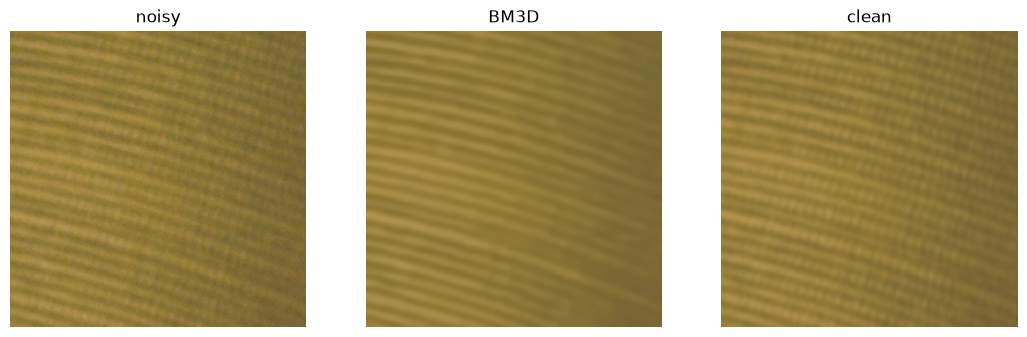

In [29]:
def denoise(image, sigma):
    return np.asarray(bm3d.bm3d_rgb(image, sigma_psd=sigma), dtype=np.float32)


start = time.perf_counter()
cleaned = denoise(check["noisy"], 0.08)
seconds = time.perf_counter() - start

print(f"took {seconds:.2f} s for one 256x256 crop")
print(f"before {psnr(check['noisy'], check['gt']):.3f} dB  ->  after {psnr(cleaned, check['gt']):.3f} dB")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (title, image) in zip(axes, [("noisy", check["noisy"]), ("BM3D", cleaned), ("clean", check["gt"])]):
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 12. Choosing sigma on the validation set

We pick sigma using validation crops only. The test scenes stay untouched until the very
end, otherwise we would be tuning on the data we report.

BM3D takes about 5 seconds per crop, and the full validation set times seven sigma values
would take over an hour, so we use a seeded subsample of 24 crops. 

In [30]:
N_CALIB = 24

calib_crops = get_crops("val", limit=N_CALIB)
print(f"{len(calib_crops)} crops x {len(SIGMA_GRID)} sigmas, roughly {len(calib_crops) * len(SIGMA_GRID) * 5 / 60:.0f} min\n")

scores = {}
for sigma in SIGMA_GRID:
    scores[sigma] = float(np.mean([psnr(denoise(c["noisy"], sigma), c["gt"]) for c in calib_crops]))
    print(f"sigma {sigma:<5} PSNR {scores[sigma]:.3f} dB")

best_sigma = max(scores, key=scores.get)
on_edge = best_sigma in (SIGMA_GRID[0], SIGMA_GRID[-1])

print(f"\nbest sigma: {best_sigma} at {scores[best_sigma]:.3f} dB")
print("warning: this is the edge of the grid" if on_edge else "good: this is inside the grid")

(results_dir / "calibration.json").write_text(
    json.dumps(
        {
            "seed": SEED,
            "n_val_crops": len(calib_crops),
            "grid": list(SIGMA_GRID),
            "psnr_by_sigma": {str(k): v for k, v in scores.items()},
            "best_sigma": best_sigma,
            "best_val_psnr": scores[best_sigma],
            "selected_at_grid_edge": on_edge,
        },
        indent=2,
    ),
    encoding="utf-8",
)
print("saved calibration.json")


24 crops x 7 sigmas, roughly 14 min

sigma 0.02  PSNR 28.470 dB
sigma 0.04  PSNR 31.733 dB
sigma 0.08  PSNR 35.672 dB
sigma 0.12  PSNR 36.861 dB
sigma 0.16  PSNR 37.176 dB
sigma 0.2   PSNR 37.191 dB
sigma 0.24  PSNR 37.099 dB

best sigma: 0.2 at 37.191 dB
good: this is inside the grid
saved calibration.json


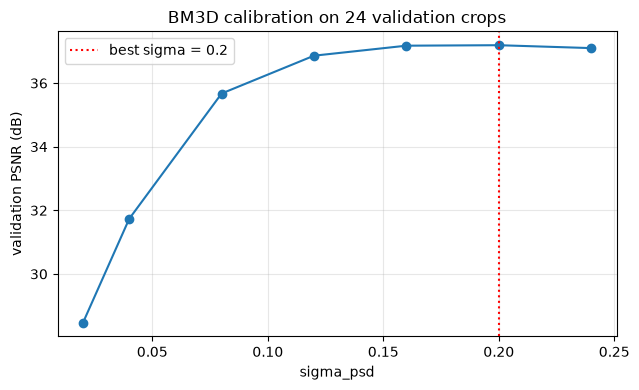

In [31]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(list(scores.keys()), list(scores.values()), marker="o")
ax.axvline(best_sigma, ls=":", color="red", label=f"best sigma = {best_sigma}")
ax.set_xlabel("sigma_psd")
ax.set_ylabel("validation PSNR (dB)")
ax.set_title(f"BM3D calibration on {len(calib_crops)} validation crops")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "calibration.png", dpi=150)
plt.show()

The curve rises steeply, flattens near the top and then starts falling again. That shape
is what tells us the chosen sigma is a real peak and not just the largest value we
happened to try.

## 13. Score on the test scenes

Sigma is fixed now. We run it once over every test crop and do not change anything after
seeing these numbers.

In [32]:
test_crops = get_crops("test")
print(f"scoring {len(test_crops)} test crops with sigma {best_sigma}\n")

noisy_psnr = [psnr(c["noisy"], c["gt"]) for c in test_crops]
noisy_ssim = [ssim(c["noisy"], c["gt"]) for c in test_crops]

bm3d_psnr, bm3d_ssim = [], []
start = time.perf_counter()
for crop in test_crops:
    cleaned = denoise(crop["noisy"], best_sigma)
    bm3d_psnr.append(psnr(cleaned, crop["gt"]))
    bm3d_ssim.append(ssim(cleaned, crop["gt"]))
elapsed = time.perf_counter() - start

results = {
    "noisy": {
        "sigma": None,
        "psnr": float(np.mean(noisy_psnr)),
        "ssim": float(np.mean(noisy_ssim)),
        "psnr_std": float(np.std(noisy_psnr)),
        "seconds_per_crop": 0.0,
    },
    "bm3d": {
        "sigma": best_sigma,
        "psnr": float(np.mean(bm3d_psnr)),
        "ssim": float(np.mean(bm3d_ssim)),
        "psnr_std": float(np.std(bm3d_psnr)),
        "ssim_std": float(np.std(bm3d_ssim)),
        "seconds_per_crop": elapsed / len(test_crops),
    },
}

print(f"{'':6s} {'PSNR dB':>9s} {'SSIM':>9s} {'s/crop':>8s}")
for name, row in results.items():
    print(f"{name:6s} {row['psnr']:9.3f} {row['ssim']:9.5f} {row['seconds_per_crop']:8.2f}")

gain = results["bm3d"]["psnr"] - results["noisy"]["psnr"]
print(f"\nBM3D gains {gain:.2f} dB over the noisy input")

scoring 156 test crops with sigma 0.2

         PSNR dB      SSIM   s/crop
noisy     28.166   0.50960     0.00
bm3d      38.440   0.93600     5.05

BM3D gains 10.27 dB over the noisy input


## 14. Why BM3D and not another classical filter

BM3D is not the only classical denoiser we could have picked. The other obvious one is
non local means, which also works by averaging similar patches but keeps them in the
pixel domain instead of transforming them.

Saying "we chose BM3D because it is the standard" is not a reason. So we run NLM through
exactly the same steps: same sigma grid, same validation crops to pick its parameter,
same test crops to score it. Then the choice is backed by a number instead of a habit.

NLM is also much faster, so if it were close we would have a real decision to make.


In [33]:
from skimage.restoration import denoise_nl_means


def denoise_nlm(image, h):
    return np.asarray(
        denoise_nl_means(image, h=h, patch_size=7, patch_distance=11, channel_axis=-1, fast_mode=True),
        dtype=np.float32,
    )


nlm_scores = {}
for h in SIGMA_GRID:
    nlm_scores[h] = float(np.mean([psnr(denoise_nlm(c["noisy"], h), c["gt"]) for c in calib_crops]))
    print(f"h {h:<5} PSNR {nlm_scores[h]:.3f} dB")

best_h = max(nlm_scores, key=nlm_scores.get)
print(f"\nbest h: {best_h} at {nlm_scores[best_h]:.3f} dB")


h 0.02  PSNR 30.356 dB
h 0.04  PSNR 34.827 dB
h 0.08  PSNR 36.027 dB
h 0.12  PSNR 35.610 dB
h 0.16  PSNR 35.238 dB
h 0.2   PSNR 34.963 dB
h 0.24  PSNR 34.773 dB

best h: 0.08 at 36.027 dB


In [34]:
nlm_psnr, nlm_ssim = [], []
start = time.perf_counter()
for crop in test_crops:
    cleaned_nlm = denoise_nlm(crop["noisy"], best_h)
    nlm_psnr.append(psnr(cleaned_nlm, crop["gt"]))
    nlm_ssim.append(ssim(cleaned_nlm, crop["gt"]))
elapsed_nlm = time.perf_counter() - start

results["nlm"] = {
    "h": best_h,
    "psnr": float(np.mean(nlm_psnr)),
    "ssim": float(np.mean(nlm_ssim)),
    "psnr_std": float(np.std(nlm_psnr)),
    "ssim_std": float(np.std(nlm_ssim)),
    "seconds_per_crop": elapsed_nlm / len(test_crops),
}

print(f"{'':6s} {'PSNR dB':>9s} {'SSIM':>9s} {'s/crop':>8s}")
for name, row in results.items():
    print(f"{name:6s} {row['psnr']:9.3f} {row['ssim']:9.5f} {row['seconds_per_crop']:8.2f}")

lead = results["bm3d"]["psnr"] - results["nlm"]["psnr"]
print(f"\nBM3D is ahead of NLM by {lead:.2f} dB")
print(f"NLM is faster by {results['bm3d']['seconds_per_crop'] / results['nlm']['seconds_per_crop']:.0f}x")


         PSNR dB      SSIM   s/crop
noisy     28.166   0.50960     0.00
bm3d      38.440   0.93600     5.05
nlm       36.717   0.92476     0.19

BM3D is ahead of NLM by 1.72 dB
NLM is faster by 27x


So BM3D wins by 1.72 dB and on SSIM as well, while NLM runs 27 times faster. For a
baseline we care about quality, not speed, because we only run it once and the number it
gives is the bar our own method has to clear. If NLM had been within a tenth of a dB the
speed would have been worth taking, but 1.72 dB is a wide gap.

That is our reason for using BM3D as the baseline from here on.

Both filters peak inside the grid, NLM at h 0.08 and BM3D at sigma 0.20, so neither is
limited by where we stopped searching. NLM also falls off quickly after its peak, losing
more than a dB by h 0.24, which is the over smoothing you would expect once the filter
starts averaging patches that are not really similar.


In [35]:
test_payload = {
    "seed": SEED,
    "n_test_crops": len(test_crops),
    "n_calibration_crops": len(calib_crops),
    "protocol": {
        "crop_size": CROP_SIZE,
        "crops_per_capture": CROPS_PER_CAPTURE,
        "border": BORDER,
        "ssim_window": SSIM_WINDOW,
        "ssim_sigma": SSIM_SIGMA,
        "ssim_use_sample_covariance": False,
    },
    "machine": {"platform": platform.platform(), "python": platform.python_version()},
    "results": results,
}
(results_dir / "test_results.json").write_text(json.dumps(test_payload, indent=2), encoding="utf-8")
print("saved test_results.json")

saved test_results.json


The spread matters as much as the average. The standard deviation across crops is large
because our two test scenes still cover very different ISO and lighting settings, and a
bright low-ISO crop is much easier than a dark high-ISO one.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(noisy_psnr, bins=20, alpha=0.6, label="noisy")
ax.hist(bm3d_psnr, bins=20, alpha=0.6, label="BM3D")
ax.set_xlabel("PSNR (dB)")
ax.set_ylabel("number of crops")
ax.set_title("Per crop PSNR on the test scenes")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "psnr_spread.png", dpi=150)
plt.show()

print(f"noisy: {np.mean(noisy_psnr):.2f} +/- {np.std(noisy_psnr):.2f} dB")
print(f"BM3D : {np.mean(bm3d_psnr):.2f} +/- {np.std(bm3d_psnr):.2f} dB")

## 15. A look at the result

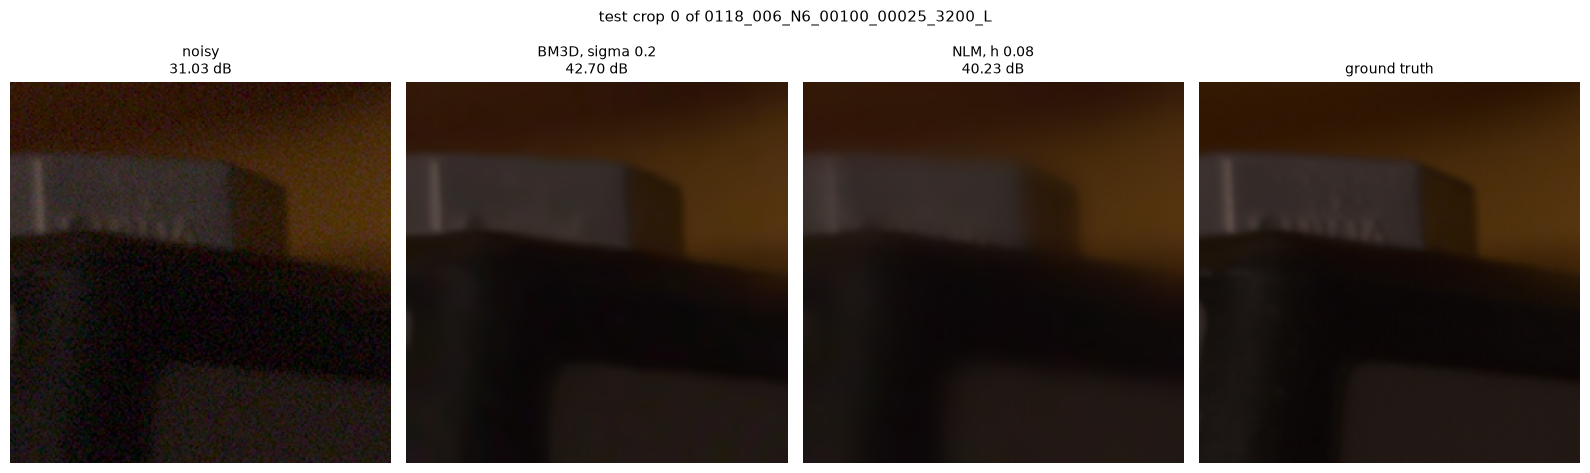

In [36]:
shown = test_crops[0]
cleaned = denoise(shown["noisy"], best_sigma)

panels = [
    ("noisy", shown["noisy"]),
    (f"BM3D, sigma {best_sigma}", cleaned),
    (f"NLM, h {best_h}", denoise_nlm(shown["noisy"], best_h)),
    ("ground truth", shown["gt"]),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
for ax, (title, image) in zip(axes, panels):
    ax.imshow(np.clip(image, 0, 1))
    score = "" if title == "ground truth" else f"\n{psnr(image, shown['gt']):.2f} dB"
    ax.set_title(title + score, fontsize=10)
    ax.axis("off")
fig.suptitle(f"test crop {shown['index']} of {shown['name']}", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(figures_dir / "qualitative.png", dpi=150)
plt.show()

## 16. Table for the report

The report reads this file directly, so the numbers in the PDF cannot drift away from the
numbers we actually measured.

In [ ]:
rows = [
    ("Noisy input", "---", results["noisy"]),
    ("BM3D", f"{best_sigma:g}", results["bm3d"]),
    ("NLM", f"{best_h:g}", results["nlm"]),
]

lines = [
    r"\begin{tabular}{@{}lcccc@{}}",
    r"\toprule",
    r"\textbf{Method} & \textbf{Parameter} & \textbf{PSNR (dB)} & \textbf{SSIM} & \textbf{s/crop} \\",
    r"\midrule",
]
for label, param_text, row in rows:
    seconds = "---" if row["seconds_per_crop"] == 0 else f"{row['seconds_per_crop']:.2f}"
    lines.append(f"{label} & {param_text} & {row['psnr']:.3f} & {row['ssim']:.4f} & {seconds} " + r"\\")
lines += [r"\bottomrule", r"\end{tabular}"]
~
table = "\n".join(lines)
(results_dir / "results_table.tex").write_text(table, encoding="utf-8")
print(table)


\begin{tabular}{@{}lcccc@{}}
\toprule
\textbf{Method} & \textbf{Parameter} & \textbf{PSNR (dB)} & \textbf{SSIM} & \textbf{s/crop} \\
\midrule
Noisy input & --- & 28.166 & 0.5096 & --- \\
BM3D & 0.2 & 38.440 & 0.9360 & 5.05 \\
NLM & 0.08 & 36.717 & 0.9248 & 0.19 \\
\bottomrule
\end{tabular}
